# LeakAudit - 09 - Figures

**Assemble the publication figures from the cached results.**

- Fig. 1 structural audit (E1-E3).
- Fig. 2 protocol collapse (E4).
- Fig. 3 outdoor-vs-indoor spectra and effect size.
- Run the relevant experiment notebooks first so the result CSVs exist.


In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import src as la
from src import config as cfg, io_utils, features, evaluation
cfg.apply_mpl_style()
X1, X1_max, M1, HZ = io_utils.load_d1()
P = cfg.PALETTE

## Fig. 1 - structural audit

C:\Users\ecredible\AppData\Local\Temp\ipykernel_24080\1243747377.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of max will be keyword-only.
  ct = pd.crosstab(M1.sid, M1.cls); purity = (ct.max(1) / ct.sum(1)).values
C:\Users\ecredible\AppData\Local\Temp\ipykernel_24080\1243747377.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(M1.sid, M1.cls); purity = (ct.max(1) / ct.sum(1)).values


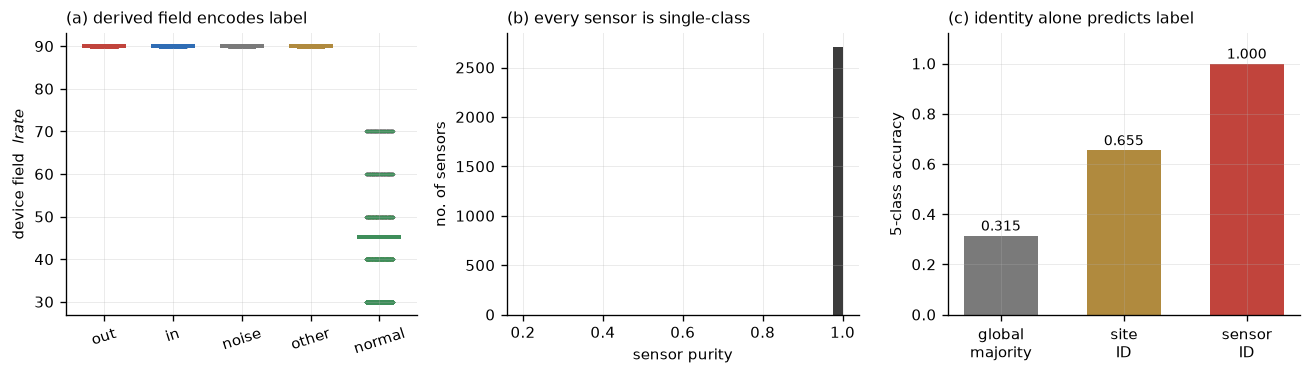

In [3]:
from sklearn.metrics import accuracy_score
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))

order = ["out", "in", "noise", "other", "normal"]
cols = [P[k if k != "in" else "inn"] for k in order]
for i, (c, col) in enumerate(zip(order, cols)):
    v = M1[M1.cls == c].lrate
    ax[0].scatter(np.full(len(v), i) + np.random.uniform(-.2, .2, len(v)),
                  v, s=1, alpha=.02, color=col, rasterized=True)
    ax[0].hlines(v.mean(), i - .32, i + .32, color=col, lw=2.4)
ax[0].set_xticks(range(5)); ax[0].set_xticklabels(order, rotation=18)
ax[0].set_ylabel("device field  $lrate$")
ax[0].set_title("(a) derived field encodes label", loc="left", fontsize=9.5)

ct = pd.crosstab(M1.sid, M1.cls); purity = (ct.max(1) / ct.sum(1)).values
ax[1].hist(purity, bins=np.linspace(.2, 1., 33), color=P["ink"], alpha=.85)
ax[1].set_xlabel("sensor purity"); ax[1].set_ylabel("no. of sensors")
ax[1].set_title("(b) every sensor is single-class", loc="left", fontsize=9.5)

maj_sid = M1.groupby("sid").cls.agg(lambda s: s.value_counts().idxmax())
maj_site = M1.groupby("site").cls.agg(lambda s: s.value_counts().idxmax())
vals = [M1.cls.value_counts(normalize=True).max(),
        accuracy_score(M1.cls, M1.site.map(maj_site)),
        accuracy_score(M1.cls, M1.sid.map(maj_sid))]
bars = ax[2].bar(["global\nmajority", "site\nID", "sensor\nID"], vals,
                 color=[P["noise"], P["other"], P["out"]], width=.6)
for r, v in zip(bars, vals):
    ax[2].text(r.get_x() + r.get_width()/2, v + .02, f"{v:.3f}", ha="center", fontsize=8.5)
ax[2].set_ylim(0, 1.12); ax[2].set_ylabel("5-class accuracy")
ax[2].set_title("(c) identity alone predicts label", loc="left", fontsize=9.5)

fig.tight_layout(); fig.savefig(cfg.FIGURES / "Fig1_structural_audit.png", bbox_inches="tight")
plt.show()

## Fig. 2 - protocol collapse

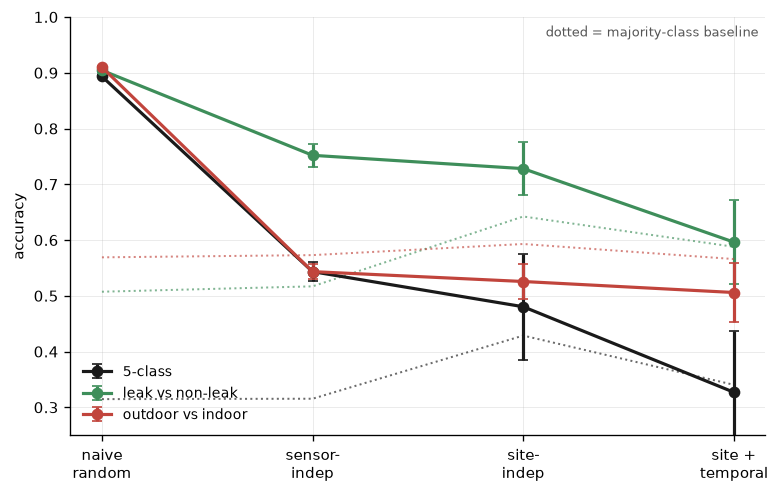

In [4]:
p = cfg.RESULTS / "E4_collapse_summary.csv"
if p.exists():
    s4 = pd.read_csv(p)
    labels = {"P1_naive_random": "naive\nrandom", "P2_sensor_indep": "sensor-\nindep",
              "P3_site_indep": "site-\nindep", "P4_site_temporal": "site +\ntemporal"}
    tasks = [("T5_five_class", "5-class", P["ink"]),
             ("TL_leak_vs_nonleak", "leak vs non-leak", P["normal"]),
             ("TR_out_vs_in", "outdoor vs indoor", P["out"])]
    fig, ax = plt.subplots(figsize=(6.6, 4.2))
    for t, lab, col in tasks:
        sub = s4[s4.task == t]
        # E4 is now run over several model families; plot the headline learner
        # so the curve describes one model rather than a mixture of four.
        if "model" in sub.columns:
            pick = "gbdt" if "gbdt" in set(sub.model) else sorted(set(sub.model))[0]
            sub = sub[sub.model == pick]
        sub = sub.set_index("protocol").reindex(evaluation.PROTOCOLS).dropna(subset=["acc"])
        xs = [evaluation.PROTOCOLS.index(i) for i in sub.index]
        ax.errorbar(xs, sub.acc, yerr=sub.acc_sd, marker="o", ms=6, lw=1.9,
                    capsize=3, color=col, label=lab)
        ax.plot(xs, sub.base, ls=":", lw=1.2, color=col, alpha=.65)
    ax.set_xticks(range(len(evaluation.PROTOCOLS)))
    ax.set_xticklabels([labels[p_] for p_ in evaluation.PROTOCOLS])
    ax.set_ylabel("accuracy"); ax.set_ylim(0.25, 1.0)
    # ax.set_title("Protocol collapse - same model, same data, same features",
                #  loc="left", fontsize=10)
    ax.legend(fontsize=8.5, loc="lower left")
    ax.text(.99, .98, "dotted = majority-class baseline", transform=ax.transAxes,
            ha="right", va="top", fontsize=7.5, color="#555")
    fig.tight_layout(); fig.savefig(cfg.FIGURES / "Fig2_protocol_collapse.png", bbox_inches="tight")
    plt.show()
else:
    print("run notebook 03 first to produce E4_collapse_summary.csv")

## Fig. 3 - outdoor vs indoor spectra

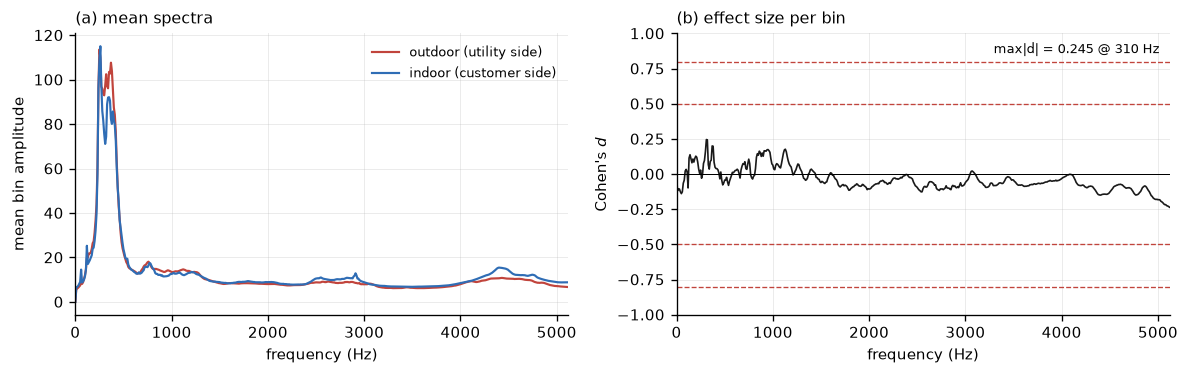

In [5]:
mo = X1[M1.cls.values == "out"].mean(0); mi = X1[M1.cls.values == "in"].mean(0)
so = X1[M1.cls.values == "out"].std(0);  si = X1[M1.cls.values == "in"].std(0)
d = (mo - mi) / (np.sqrt((so**2 + si**2) / 2) + 1e-9)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(HZ, mo, color=P["out"], lw=1.3, label="outdoor (utility side)")
ax[0].plot(HZ, mi, color=P["inn"], lw=1.3, label="indoor (customer side)")
ax[0].set_xlim(0, HZ.max()); ax[0].set_xlabel("frequency (Hz)")
ax[0].set_ylabel("mean bin amplitude")
ax[0].legend(fontsize=8); ax[0].set_title("(a) mean spectra", loc="left", fontsize=9.5)

ax[1].plot(HZ, d, color=P["ink"], lw=1.0); ax[1].axhline(0, c="k", lw=.6)
for t in (.5, .8):
    ax[1].axhline(t, ls="--", c=P["out"], lw=.8); ax[1].axhline(-t, ls="--", c=P["out"], lw=.8)
ax[1].set_ylim(-1, 1); ax[1].set_xlim(0, HZ.max())
ax[1].set_xlabel("frequency (Hz)"); ax[1].set_ylabel("Cohen's $d$")
ax[1].set_title("(b) effect size per bin", loc="left", fontsize=9.5)
ax[1].text(.98, .93, f"max|d| = {np.abs(d).max():.3f} @ {HZ[np.abs(d).argmax()]} Hz",
           transform=ax[1].transAxes, ha="right", fontsize=8)
fig.tight_layout(); fig.savefig(cfg.FIGURES / "Fig3_out_vs_in_spectra.png", bbox_inches="tight")
plt.show()

## Fig. 4 - protocol choice dominates model choice

The four learners are separated by up to 27 accuracy points under a naive
random split. Under the deployment protocol they converge to within about one
point of each other, at or below the majority-class baseline. Reporting the
between-model spread at each protocol makes the point directly: the differences
the field competes over are not measurable once the evaluation reflects
deployment.

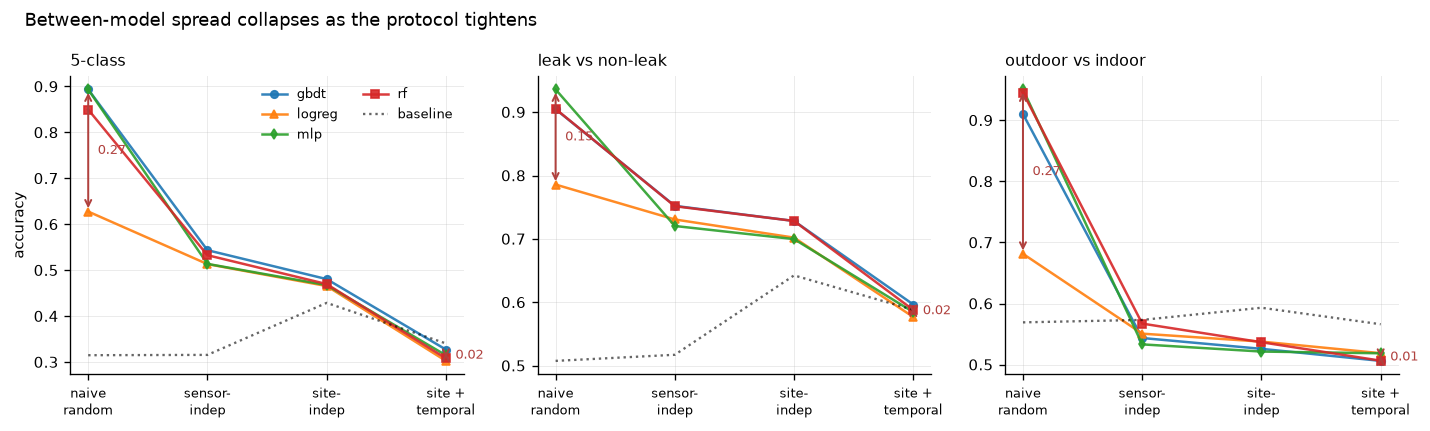

between-model spread per protocol:
  5-class              naive_random=0.266  sensor_indep=0.030  site_indep=0.015  site_temporal=0.025   ratio 10.8x
  leak vs non-leak     naive_random=0.150  sensor_indep=0.032  site_indep=0.029  site_temporal=0.020   ratio 7.6x
  outdoor vs indoor    naive_random=0.269  sensor_indep=0.034  site_indep=0.016  site_temporal=0.013   ratio 21.4x


In [6]:
p = cfg.RESULTS / "E4_collapse_summary.csv"
if p.exists() and "model" in pd.read_csv(p).columns:
    s4 = pd.read_csv(p)
    nice = {"P1_naive_random": "naive\nrandom", "P2_sensor_indep": "sensor-\nindep",
            "P3_site_indep": "site-\nindep", "P4_site_temporal": "site +\ntemporal"}
    tasks = [("T5_five_class", "5-class"),
             ("TL_leak_vs_nonleak", "leak vs non-leak"),
             ("TR_out_vs_in", "outdoor vs indoor")]
    mstyle = {"gbdt": "-o", "rf": "-s", "logreg": "-^", "mlp": "-d"}

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=False)
    for ax, (t, lab) in zip(axes, tasks):
        sub = s4[s4.task == t]
        for mdl in sorted(sub.model.unique()):
            g = sub[sub.model == mdl].set_index("protocol").reindex(
                evaluation.PROTOCOLS).dropna(subset=["acc"])
            xs = [evaluation.PROTOCOLS.index(i) for i in g.index]
            ax.plot(xs, g.acc, mstyle.get(mdl, "-o"), ms=4.5, lw=1.5,
                    label=mdl, alpha=.9)
        gb = sub[sub.model == sub.model.iloc[0]].set_index("protocol").reindex(
            evaluation.PROTOCOLS).dropna(subset=["base"])
        ax.plot([evaluation.PROTOCOLS.index(i) for i in gb.index], gb.base,
                ls=":", lw=1.4, color="k", alpha=.6, label="baseline")
        # Annotate how far apart the models are at each end.
        for prot, xpos in [("P1_naive_random", 0), ("P4_site_temporal", 3)]:
            v = sub[sub.protocol == prot].acc
            if len(v):
                ax.annotate("", xy=(xpos, v.max()), xytext=(xpos, v.min()),
                            arrowprops=dict(arrowstyle="<->", color="#B0413E", lw=1.2))
                ax.text(xpos + .08, (v.max() + v.min()) / 2,
                        f"{v.max()-v.min():.2f}", fontsize=8, color="#B0413E",
                        va="center")
        ax.set_xticks(range(4))
        ax.set_xticklabels([nice[q] for q in evaluation.PROTOCOLS], fontsize=8)
        ax.set_title(lab, loc="left", fontsize=9.5)
        if ax is axes[0]:
            ax.set_ylabel("accuracy")
            ax.legend(fontsize=7.5, loc="upper right", ncol=2)
    fig.suptitle("Between-model spread collapses as the protocol tightens",
                 x=0.02, ha="left", fontsize=10.5)
    fig.tight_layout()
    fig.savefig(cfg.FIGURES / "Fig4_protocol_dominates_model.png",
                bbox_inches="tight")
    plt.show()

    print("between-model spread per protocol:")
    for t, lab in tasks:
        sub = s4[s4.task == t]
        sp = {q: float(sub[sub.protocol == q].acc.max() -
                       sub[sub.protocol == q].acc.min())
              for q in evaluation.PROTOCOLS if (sub.protocol == q).any()}
        rng = f"{sp[evaluation.PROTOCOLS[0]]/sp[evaluation.PROTOCOLS[-1]]:.1f}x" \
            if sp.get(evaluation.PROTOCOLS[-1]) else "n/a"
        print(f"  {lab:20s} " +
              "  ".join(f"{q.split('_',1)[1]}={v:.3f}" for q, v in sp.items()) +
              f"   ratio {rng}")
else:
    print("run notebook 03 first (needs the per-model summary)")

## Variance attribution - protocol against model

The between-model spread shrinks as the protocol tightens, but quoting a ratio
of marginal-mean variances is not a variance decomposition: it ignores the
protocol x model interaction and the seed-to-seed variation. We therefore fit a
factorial model on the raw runs and report the sum-of-squares share and partial
eta-squared for each term, which is what a statistical reviewer will expect.

In [7]:
p = cfg.RESULTS / "E4_collapse.csv"
if p.exists():
    d4raw = pd.read_csv(p)
    have_model = "model" in d4raw.columns and d4raw.model.nunique() > 1
    if not have_model:
        print("E4 was run with a single model; re-run notebook 03 with four "
              "model families to attribute variance.")
    else:
        rows = []
        for task, g in d4raw.groupby("task"):
            y = g.acc.to_numpy()
            gm = y.mean()
            ss_total = ((y - gm) ** 2).sum()

            # Main effects and interaction, computed from cell means.
            prot_mean = g.groupby("protocol").acc.transform("mean")
            mod_mean = g.groupby("model").acc.transform("mean")
            cell_mean = g.groupby(["protocol", "model"]).acc.transform("mean")

            ss_prot = ((prot_mean - gm) ** 2).sum()
            ss_mod = ((mod_mean - gm) ** 2).sum()
            ss_int = ((cell_mean - prot_mean - mod_mean + gm) ** 2).sum()
            ss_resid = ((g.acc - cell_mean) ** 2).sum()   # seed-to-seed

            n_p = g.protocol.nunique(); n_m = g.model.nunique()
            df_p, df_m = n_p - 1, n_m - 1
            df_i = df_p * df_m
            df_r = len(g) - n_p * n_m

            for name, ss, df in [("protocol", ss_prot, df_p),
                                 ("model", ss_mod, df_m),
                                 ("protocol x model", ss_int, df_i),
                                 ("residual (seed)", ss_resid, df_r)]:
                rows.append(dict(task=task, term=name, ss=ss, df=df,
                                 ss_share=ss / ss_total,
                                 partial_eta2=ss / (ss + ss_resid)))

        va = pd.DataFrame(rows)
        print(va.round(4).to_string(index=False))
        va.to_csv(cfg.RESULTS / "E4_variance_attribution.csv", index=False)

        print("\nprotocol share vs model share (sum-of-squares):")
        for task, g in va.groupby("task"):
            sp = float(g[g.term == "protocol"].ss_share.iloc[0])
            sm = float(g[g.term == "model"].ss_share.iloc[0])
            si = float(g[g.term == "protocol x model"].ss_share.iloc[0])
            print(f"  {task:20s} protocol {sp:6.1%}   model {sm:6.1%}   "
                  f"interaction {si:6.1%}   ratio {sp/sm:5.1f}x")
        print("\n-> Report the shares and partial eta-squared, not a bare ratio of")
        print("   marginal-mean variances: the interaction term is not negligible")
        print("   and belongs in any statement about which factor matters more.")
else:
    print("run notebook 03 first")

              task             term     ss  df  ss_share  partial_eta2
     T5_five_class         protocol 5.2938   3    0.8095        0.8761
     T5_five_class            model 0.1661   3    0.0254        0.1816
     T5_five_class protocol x model 0.3313   9    0.0507        0.3069
     T5_five_class  residual (seed) 0.7484 144    0.1144        0.5000
TL_leak_vs_nonleak         protocol 1.7711   3    0.7913        0.8478
TL_leak_vs_nonleak            model 0.0563   3    0.0252        0.1505
TL_leak_vs_nonleak protocol x model 0.0927   9    0.0414        0.2258
TL_leak_vs_nonleak  residual (seed) 0.3180 144    0.1421        0.5000
      TR_out_vs_in         protocol 3.5214   3    0.8414        0.9563
      TR_out_vs_in            model 0.1080   3    0.0258        0.4019
      TR_out_vs_in protocol x model 0.3949   9    0.0943        0.7106
      TR_out_vs_in  residual (seed) 0.1608 144    0.0384        0.5000

protocol share vs model share (sum-of-squares):
  T5_five_class        proto